In [2]:
# uplaod all codes
from google.colab import files
from pathlib import Path
from datetime import datetime
import zipfile

uploaded = files.upload()

zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_names:
    raise ValueError("Please upload your project ZIP file(s).")

work_folder = (
    Path("/content")
    / ("chain_project_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
)
work_folder.mkdir(parents=True, exist_ok=True)

for index, name in enumerate(zip_names, start=1):
    destination = work_folder / f"upload_{index}"
    destination.mkdir()

    with zipfile.ZipFile(name) as archive:
        # Check that all extracted paths stay inside the destination.
        for member in archive.infolist():
            target = (destination / member.filename).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError(f"Unsafe archive path: {member.filename}")

        archive.extractall(destination)

    print(f"Extracted: {name}")
    print(f"Location: {destination}\n")

# Release uploaded ZIP bytes from notebook memory
del uploaded

Saving bme_507_final_project-cable_model.zip to bme_507_final_project-cable_model (1).zip
Saving bme_507_final_project-CiPA_python (2).zip to bme_507_final_project-CiPA_python (2).zip
Extracted: bme_507_final_project-cable_model (1).zip
Location: /content/chain_project_20261118_035131/upload_1

Extracted: bme_507_final_project-CiPA_python (2).zip
Location: /content/chain_project_20261118_035131/upload_2



In [1]:
# identify drug+beta file and chain file
import re

ignored_parts = {
    "__MACOSX", ".git", ".venv", "venv",
    "__pycache__", "node_modules"
}

def usable(path):
    return not any(part in ignored_parts for part in path.parts)

all_files = sorted(
    path for path in work_folder.rglob("*")
    if path.is_file() and usable(path)
)

print("=== INSTALLATION FILES ===")
for path in all_files:
    if path.name in {
        "pyproject.toml", "requirements.txt",
        "setup.py", "environment.yml"
    }:
        print(path.relative_to(work_folder))
        print(path.read_text(errors="replace")[:6000])
        print()

print("\n=== COMBINED CELL MODEL ===")
combined_cells = [
    path for path in all_files
    if path.name == "cell.py" and path.parent.name == "cipa_beta"
]
for path in combined_cells:
    print(path.relative_to(work_folder))

if not combined_cells:
    print("No cipa_beta/cell.py found.")

print("\n=== PYTHON AND NOTEBOOK FILES ===")
code_files = [
    path for path in all_files
    if path.suffix in {".py", ".ipynb"}
]
for path in code_files[:150]:
    print(path.relative_to(work_folder))

if len(code_files) > 150:
    print(f"... {len(code_files) - 150} additional files omitted.")

print("\n=== POSSIBLE CHAIN / TISSUE FILES ===")
pattern = re.compile(
    r"chain|cable|tissue|monodomain|diffusion|"
    r"gap.junction|conductance|laplacian",
    re.IGNORECASE
)

matches = []
for path in code_files:
    if path.suffix == ".py":
        content = path.read_text(errors="replace")
        if pattern.search(path.name) or pattern.search(content):
            matches.append(path)
    elif pattern.search(path.name):
        matches.append(path)

for path in matches[:40]:
    print(path.relative_to(work_folder))

if not matches:
    print("No obvious chain files found; inspect the notebook list above.")

NameError: name 'work_folder' is not defined

In [4]:
# install and load the combined model
import os
import sys
import subprocess
import importlib
import numpy as np
import matplotlib.pyplot as plt

# Locate the combined model in your extracted uploads.
candidates = [
    path.parent.parent
    for path in work_folder.rglob("cipa_beta/cell.py")
    if "__MACOSX" not in path.parts
]

if len(candidates) != 1:
    raise RuntimeError(
        f"Expected one combined model; found {len(candidates)}."
    )

project_folder = candidates[0]
os.chdir(project_folder)

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "-q", "-e", str(project_folder)
])

sys.path.insert(0, str(project_folder))
importlib.invalidate_caches()

from cipa_beta.cell import CiPABetaCell
from cipa.models import ap_parameters, parameter_vector
from scipy.integrate import solve_ivp
from scipy.sparse import lil_matrix

print("Project:", project_folder)
print("States per cell:", len(CiPABetaCell.state_names))
assert len(CiPABetaCell.state_names) == 124

Project: /content/chain_project_20261118_035131/upload_2/bme_507_final_project-CiPA_python
States per cell: 124


In [9]:
# applies ISO and quinidine uniformly, stimulates only the first few cells, and lets voltage spread through neighbor coupling
def run_beta_chain(
    iso=0.0,
    quinidine_nM=0.0,
    n_cells=10,
    beats=1,
    cycle_length=2000.0,
    D_gap=0.0012,       # cm²/ms; from TY
    dx=0.01,            # cm; from TY
    stimulated_cells=3,
    record_dt=0.5,      # saved output spacing, ms
    ##### CHANGE
        stimulus_duration=0.5,  # ms
    rtol=1e-6,
    atol=1e-9,
    max_step=2.0,          # ms
    ##### CHANGE
):
    if not 1 <= stimulated_cells <= n_cells:
        raise ValueError("Invalid number of stimulated cells.")

    model = CiPABetaCell(iso=iso)
    ##### CHANGE
    model.stimulus_duration = float(stimulus_duration)

    if not 0 < model.stimulus_duration < cycle_length:
        raise ValueError("Stimulus duration must be between 0 and cycle length.")
    ##### CHANGE
    names = list(model.state_names)
    n_states = len(names)
    voltage_index = names.index("v")
    calcium_index = names.index("cai")

    drug = "control" if quinidine_nM == 0 else "quinidine"

    parameters = parameter_vector(ap_parameters(
        drug=drug,
        concentration=quinidine_nM,
        hergpath=str(project_folder / "results/herg"),
        hillpath=str(project_folder / "results/hill"),
        optimized=True,
    ))

    print("Preparing signaling and initial states...", flush=True)
    initial = model.initial_state(quinidine_nM)
    states = np.tile(initial, (n_cells, 1))

    # Each cell's states can depend on its other states.
    # Neighbor dependence occurs only through voltage.
    size = n_cells * n_states
    sparsity = lil_matrix((size, size), dtype=int)

    for cell in range(n_cells):
        start = cell * n_states
        sparsity[start:start+n_states, start:start+n_states] = 1

        for neighbor in (cell - 1, cell + 1):
            if 0 <= neighbor < n_cells:
                sparsity[
                    start + voltage_index,
                    neighbor * n_states + voltage_index
                ] = 1

    sparsity = sparsity.tocsr()
    saved_t, saved_v, saved_ca = [], [], []

    for beat in range(beats):
        beat_start = beat * cycle_length

        # Explicitly split stimulus-on and stimulus-off intervals.
        segments = [
            (0.0, model.stimulus_duration, True),
            (model.stimulus_duration, cycle_length, False),
        ]

        for start, stop, stimulus_on in segments:

            def rhs(t, flat_states):
                cells = flat_states.reshape(n_cells, n_states)
                derivatives = np.empty_like(cells)

                for cell in range(n_cells):
                    stimulated = (
                        stimulus_on and cell < stimulated_cells
                    )
                    derivatives[cell] = model.evaluate(
                        t, cells[cell], parameters, stimulated
                    )[0]

                # TY's sealed-end nearest-neighbor coupling.
                # Equal and opposite contributions conserve the
                # sum of voltage-coupling terms across the chain.
                voltage = cells[:, voltage_index]
                edge_flux = (
                    D_gap / dx**2 * np.diff(voltage)
                )
                derivatives[:-1, voltage_index] += edge_flux
                derivatives[1:, voltage_index] -= edge_flux

                return derivatives.ravel()

            local_times = np.unique(np.r_[
                start,
                np.arange(start, stop, record_dt),
                stop,
            ])

            solution = solve_ivp(
                rhs,
                (beat_start + start, beat_start + stop),
                states.ravel(),
                method="BDF",
                t_eval=beat_start + local_times,
                ##### rtol=1e-6,
                ##### atol=1e-9,
                ##### max_step=2.0,
                ##### CHANGED
                rtol=rtol,
                atol=atol,
                max_step=max_step,
                ##### CHANGED
                jac_sparsity=sparsity,
            )

            if not solution.success:
                raise RuntimeError(solution.message)

            if not np.isfinite(solution.y).all():
                raise RuntimeError("Nonfinite model states detected.")

            trajectory = solution.y.T.reshape(
                -1, n_cells, n_states
            )
            states = trajectory[-1].copy()

            # Avoid duplicate times at segment/beat boundaries.
            keep = slice(None) if not saved_t else slice(1, None)

            saved_t.append(solution.t[keep])
            saved_v.append(trajectory[keep, :, voltage_index])
            saved_ca.append(trajectory[keep, :, calcium_index])

        # Retain the cell model's normal beat-reset behavior.
        states = np.stack([
            model.reset_beat(cell.copy()) for cell in states
        ])

        print(f"Completed beat {beat + 1}/{beats}", flush=True)

    return {
        "time_ms": np.concatenate(saved_t),
        "voltage_mV": np.concatenate(saved_v),
        "calcium_mM": np.concatenate(saved_ca),
        "final_states": states,
        "iso_uM": iso,
        "quinidine_nM": quinidine_nM,
        "dx_cm": dx,
        "stimulated_cells": stimulated_cells,
    }

In [10]:
# baseline startup test - 10 endocardial cells, one beat, no quinidine, ISO 0. The first three receive the stimulus
baseline_chain = run_beta_chain(
    iso=0,
    quinidine_nM=0,
    n_cells=10,
    stimulated_cells=3,
    beats=1,
)

print("Baseline chain finished.")

Preparing signaling and initial states...
Completed beat 1/1
Baseline chain finished.


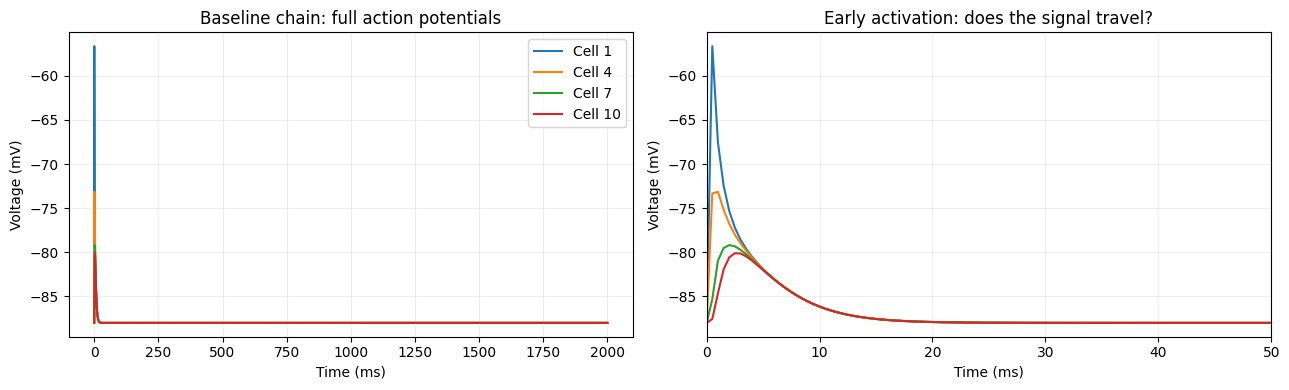

Peak voltage by cell (mV):
[-56.6 -59.2 -64.6 -73.2 -75.9 -78.1 -79.2 -79.7 -80.  -80.1]


In [11]:
# check whether signal propogates
result = baseline_chain
t = result["time_ms"]
v = result["voltage_mV"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for cell in [0, 3, 6, 9]:
    label = f"Cell {cell + 1}"
    axes[0].plot(t, v[:, cell], label=label)
    axes[1].plot(t, v[:, cell], label=label)

axes[0].set_title("Baseline chain: full action potentials")
axes[1].set_title("Early activation: does the signal travel?")
axes[1].set_xlim(0, 50)

for ax in axes:
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Voltage (mV)")
    ax.grid(alpha=0.2)

axes[0].legend()
plt.tight_layout()
plt.show()

print("Peak voltage by cell (mV):")
print(np.round(v.max(axis=0), 1))

In [13]:
# CELL 7
# set a plotting helper - so every test the same voltage scale so that a small bump cannot look like a full action potential
def inspect_chain(result, title):
    t = result["time_ms"]
    v = result["voltage_mV"]
    n_cells = v.shape[1]

    selected = sorted(set([0, n_cells // 2, n_cells - 1]))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    for cell in selected:
        for ax in axes:
            ax.plot(t, v[:, cell], label=f"Cell {cell + 1}")

    axes[0].set_title(title)
    axes[1].set_title("First 50 ms")
    axes[1].set_xlim(0, 50)

    for ax in axes:
        ax.set_ylim(-100, 60)
        ax.set_xlabel("Time (ms)")
        ax.set_ylabel("Voltage (mV)")
        ax.grid(alpha=0.2)

    axes[0].legend()
    plt.tight_layout()
    plt.show()

    peaks = v.max(axis=0)
    print("Peak voltage by cell (mV):")
    print(np.round(peaks, 1))

    # Screening flag only—not a full action-potential validation.
    print("Cells reaching positive voltage:",
          (np.flatnonzero(peaks > 0) + 1).tolist())

Preparing signaling and initial states...
Completed beat 1/1


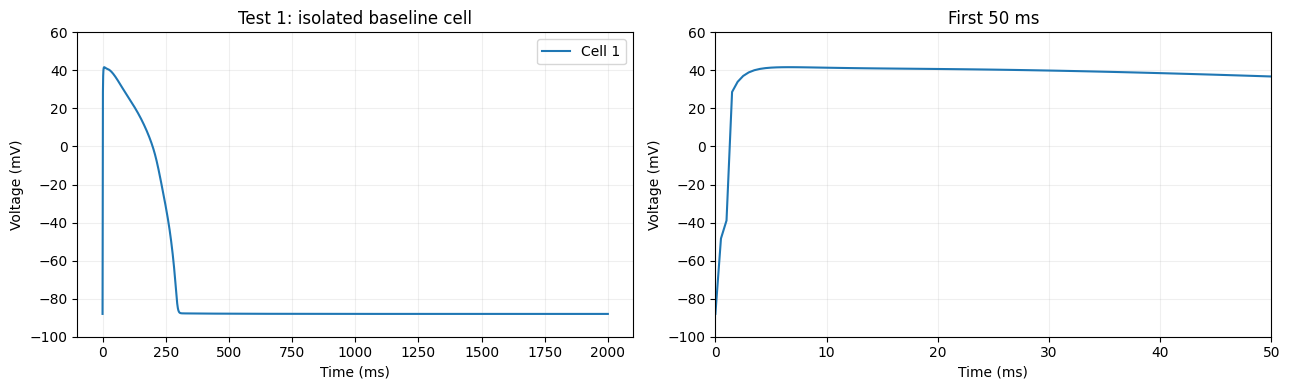

Peak voltage by cell (mV):
[41.7]
Cells reaching positive voltage: [1]


In [14]:
# test on one isolated cell
isolated = run_beta_chain(
    iso=0,
    quinidine_nM=0,
    n_cells=1,
    stimulated_cells=1,
    D_gap=0,
    beats=1,
    stimulus_duration=0.5,
)

inspect_chain(isolated, "Test 1: isolated baseline cell")

Preparing signaling and initial states...
Completed beat 1/1


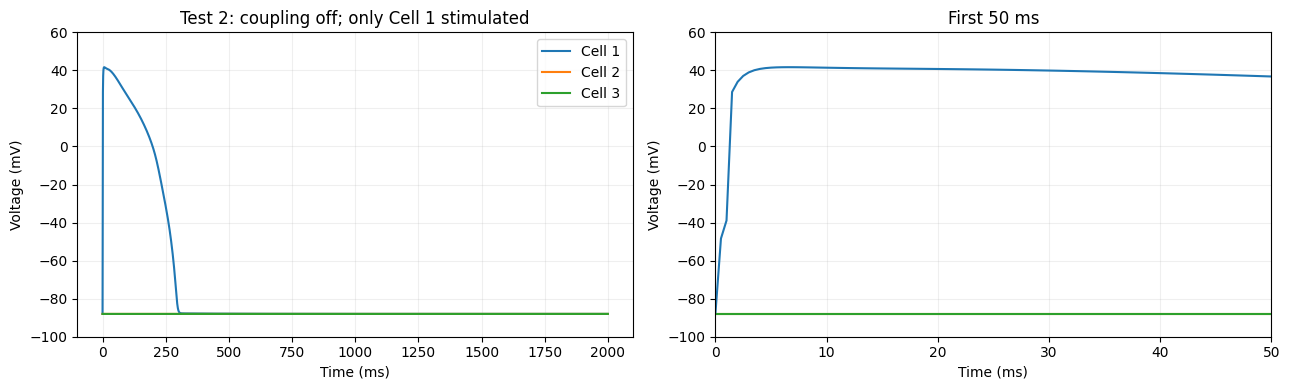

Peak voltage by cell (mV):
[ 41.7 -88.  -88. ]
Cells reaching positive voltage: [1]
Maximum stimulated-cell difference from isolated run: 0.0008407 mV


In [15]:
# coupling off, 3 cells, only simulate cell 1 no drug, no iso
uncoupled = run_beta_chain(
    iso=0,
    quinidine_nM=0,
    n_cells=3,
    stimulated_cells=1,
    D_gap=0,
    beats=1,
    stimulus_duration=0.5,
)

inspect_chain(
    uncoupled,
    "Test 2: coupling off; only Cell 1 stimulated"
)

difference = np.max(np.abs(
    uncoupled["voltage_mV"][:, 0]
    - isolated["voltage_mV"][:, 0]
))

print(
    "Maximum stimulated-cell difference from isolated run:",
    f"{difference:.4g} mV"
)

Preparing signaling and initial states...
Completed beat 1/1


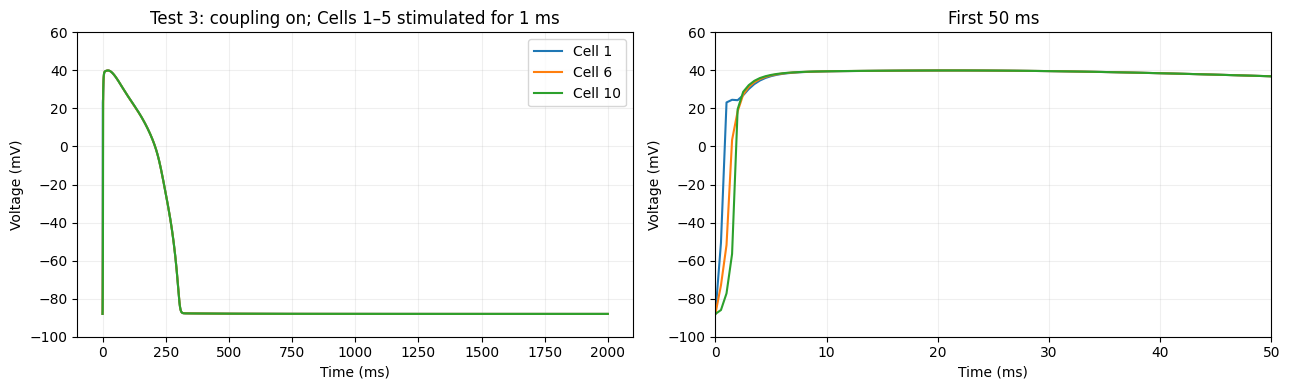

Peak voltage by cell (mV):
[40. 40. 40. 40. 40. 40. 40. 40. 40. 40.]
Cells reaching positive voltage: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [16]:
# reconnect 10 cells, stimulate the first 5 cells for 1 ms
# keep the 2000 ms pacing interval used in single cell experiments
coupled = run_beta_chain(
    iso=0,
    quinidine_nM=0,
    n_cells=10,
    stimulated_cells=5,
    D_gap=0.0012,
    dx=0.01,
    beats=1,
    stimulus_duration=1.0,
)

inspect_chain(
    coupled,
    "Test 3: coupling on; Cells 1–5 stimulated for 1 ms"
)

Preparing signaling and initial states...
Completed beat 1/1


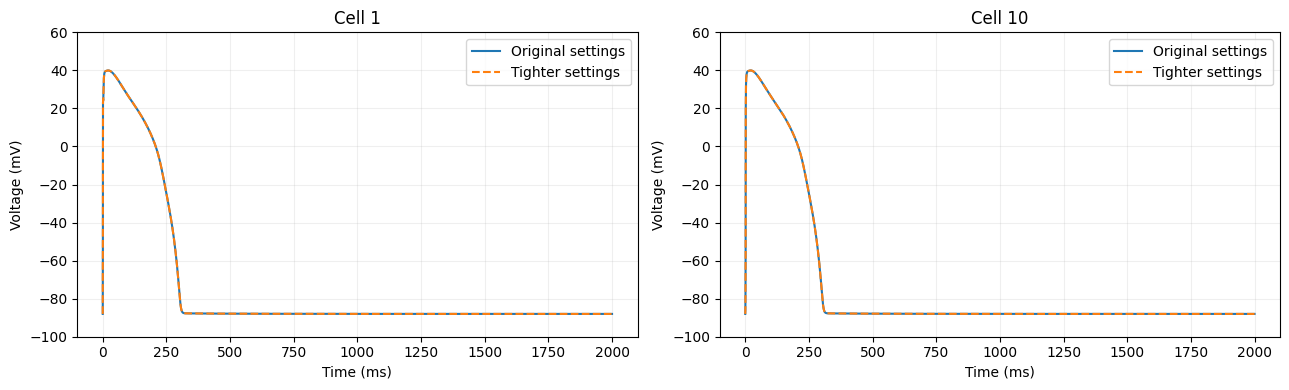

In [17]:
# tighter solver setting
coupled_tight = run_beta_chain(
    iso=0,
    quinidine_nM=0,
    n_cells=10,
    stimulated_cells=5,
    D_gap=0.0012,
    dx=0.01,
    beats=1,
    stimulus_duration=1.0,
    rtol=1e-7,
    atol=1e-10,
    max_step=0.5,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, cell in zip(axes, [0, 9]):
    ax.plot(
        coupled["time_ms"],
        coupled["voltage_mV"][:, cell],
        label="Original settings"
    )
    ax.plot(
        coupled_tight["time_ms"],
        coupled_tight["voltage_mV"][:, cell],
        "--", label="Tighter settings"
    )
    ax.set_title(f"Cell {cell + 1}")
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Voltage (mV)")
    ax.set_ylim(-100, 60)
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

In [19]:
# run 50 cells baseline
from time import perf_counter

chain_settings = dict(
    n_cells=50,
    stimulated_cells=5,
    beats=1,
    cycle_length=2000.0,   # ms
    stimulus_duration=1.0, # ms
    D_gap=0.0012,          # cm²/ms
    dx=0.01,              # cm
    record_dt=0.5,        # saved sampling interval, ms
    rtol=1e-6,
    atol=1e-9,
    max_step=2.0,
)

start = perf_counter()

baseline_50 = run_beta_chain(
    iso=0,
    quinidine_nM=0,
    **chain_settings
)

print(f"Elapsed: {(perf_counter() - start)/60:.1f} minutes")

Preparing signaling and initial states...
Completed beat 1/1
Elapsed: 6.0 minutes


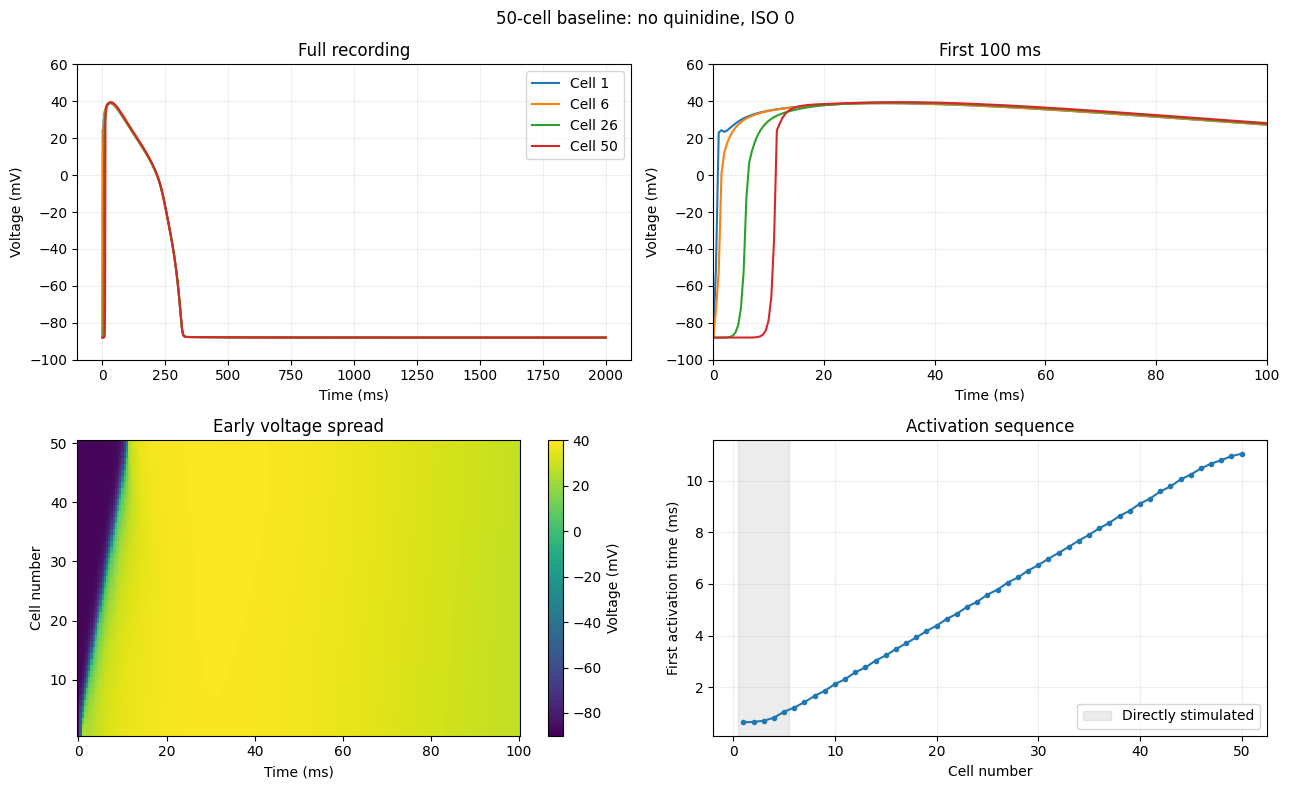

Cells crossing −30 mV: 50/50
Cells reaching positive voltage: 50/50


,cell,peak_voltage_mV,activation_time_ms,final_voltage_mV
0,1,38.946319,0.639874,-88.014778
4,5,38.964589,1.050095,-88.014744
5,6,38.972892,1.210012,-88.014712
25,26,39.260875,5.778579,-88.014643
49,50,39.503140,11.039145,-88.014138


In [20]:
# plot propagation and measure activation times
import pandas as pd

def first_activation_times(result, threshold=-30.0):
    t = result["time_ms"]
    v = result["voltage_mV"]
    activation = np.full(v.shape[1], np.nan)

    for cell in range(v.shape[1]):
        crossings = np.flatnonzero(
            (v[:-1, cell] < threshold) &
            (v[1:, cell] >= threshold)
        )

        if crossings.size:
            i = crossings[0]
            fraction = (
                (threshold - v[i, cell]) /
                (v[i + 1, cell] - v[i, cell])
            )
            activation[cell] = (
                t[i] + fraction * (t[i + 1] - t[i])
            )

    return activation


def plot_chain_overview(result, title):
    t = result["time_ms"]
    v = result["voltage_mV"]
    n_cells = v.shape[1]
    cell_numbers = np.arange(1, n_cells + 1)
    activation = first_activation_times(result)

    fig, axes = plt.subplots(2, 2, figsize=(13, 8))

    selected = sorted(set([
        0,
        result["stimulated_cells"],  # first unstimulated cell
        n_cells // 2,
        n_cells - 1,
    ]))

    for cell in selected:
        if cell >= n_cells:
            continue
        for ax in axes[0]:
            ax.plot(t, v[:, cell], label=f"Cell {cell + 1}")

    axes[0, 0].set_title("Full recording")
    axes[0, 1].set_title("First 100 ms")
    axes[0, 1].set_xlim(0, 100)

    for ax in axes[0]:
        ax.set_ylim(-100, 60)
        ax.set_xlabel("Time (ms)")
        ax.set_ylabel("Voltage (mV)")
        ax.grid(alpha=0.2)

    axes[0, 0].legend()

    early = t <= 100
    heatmap = axes[1, 0].pcolormesh(
        t[early], cell_numbers, v[early].T,
        shading="auto", cmap="viridis",
        vmin=-90, vmax=40
    )
    axes[1, 0].set_xlabel("Time (ms)")
    axes[1, 0].set_ylabel("Cell number")
    axes[1, 0].set_title("Early voltage spread")
    fig.colorbar(
        heatmap, ax=axes[1, 0], label="Voltage (mV)"
    )

    axes[1, 1].plot(
        cell_numbers, activation, "o-", markersize=3
    )
    axes[1, 1].axvspan(
        0.5, result["stimulated_cells"] + 0.5,
        color="gray", alpha=0.15,
        label="Directly stimulated"
    )
    axes[1, 1].set_xlabel("Cell number")
    axes[1, 1].set_ylabel("First activation time (ms)")
    axes[1, 1].set_title("Activation sequence")
    axes[1, 1].legend()
    axes[1, 1].grid(alpha=0.2)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

    summary = pd.DataFrame({
        "cell": cell_numbers,
        "peak_voltage_mV": v.max(axis=0),
        "activation_time_ms": activation,
        "final_voltage_mV": v[-1],
    })

    print(
        f"Cells crossing −30 mV: "
        f"{np.isfinite(activation).sum()}/{n_cells}"
    )
    print(
        f"Cells reaching positive voltage: "
        f"{(v.max(axis=0) > 0).sum()}/{n_cells}"
    )
    display(summary.iloc[[0, 4, 5, n_cells//2, n_cells-1]])

    return summary


baseline_50_summary = plot_chain_overview(
    baseline_50,
    "50-cell baseline: no quinidine, ISO 0"
)

In [21]:
# three conditions
baseline_activation = first_activation_times(baseline_50)

if (
    not np.isfinite(baseline_activation).all()
    or not np.all(baseline_50["voltage_mV"].max(axis=0) > 0)
):
    raise RuntimeError(
        "Baseline did not pass the activation screen. "
        "Inspect it before starting drug comparisons."
    )

# Keep completed runs if this cell is rerun after an interruption.
if "four_condition_results" not in globals():
    four_condition_results = {}

four_condition_results["Baseline"] = baseline_50

conditions = [
    ("ISO alone",           1.0,    0.0),
    ("Quinidine alone",     0.0, 3237.0),
    ("Quinidine + ISO",     1.0, 3237.0),
]

for label, iso, quinidine in conditions:
    if label in four_condition_results:
        print(f"Already completed: {label}")
        continue

    print(f"\nStarting: {label}", flush=True)
    start = perf_counter()

    four_condition_results[label] = run_beta_chain(
        iso=iso,
        quinidine_nM=quinidine,
        **chain_settings
    )

    print(
        f"Finished {label}: "
        f"{(perf_counter() - start)/60:.1f} minutes",
        flush=True
    )


Starting: ISO alone
Preparing signaling and initial states...
Completed beat 1/1
Finished ISO alone: 5.9 minutes

Starting: Quinidine alone
Preparing signaling and initial states...
Completed beat 1/1
Finished Quinidine alone: 4.5 minutes

Starting: Quinidine + ISO
Preparing signaling and initial states...
Completed beat 1/1
Finished Quinidine + ISO: 3.8 minutes


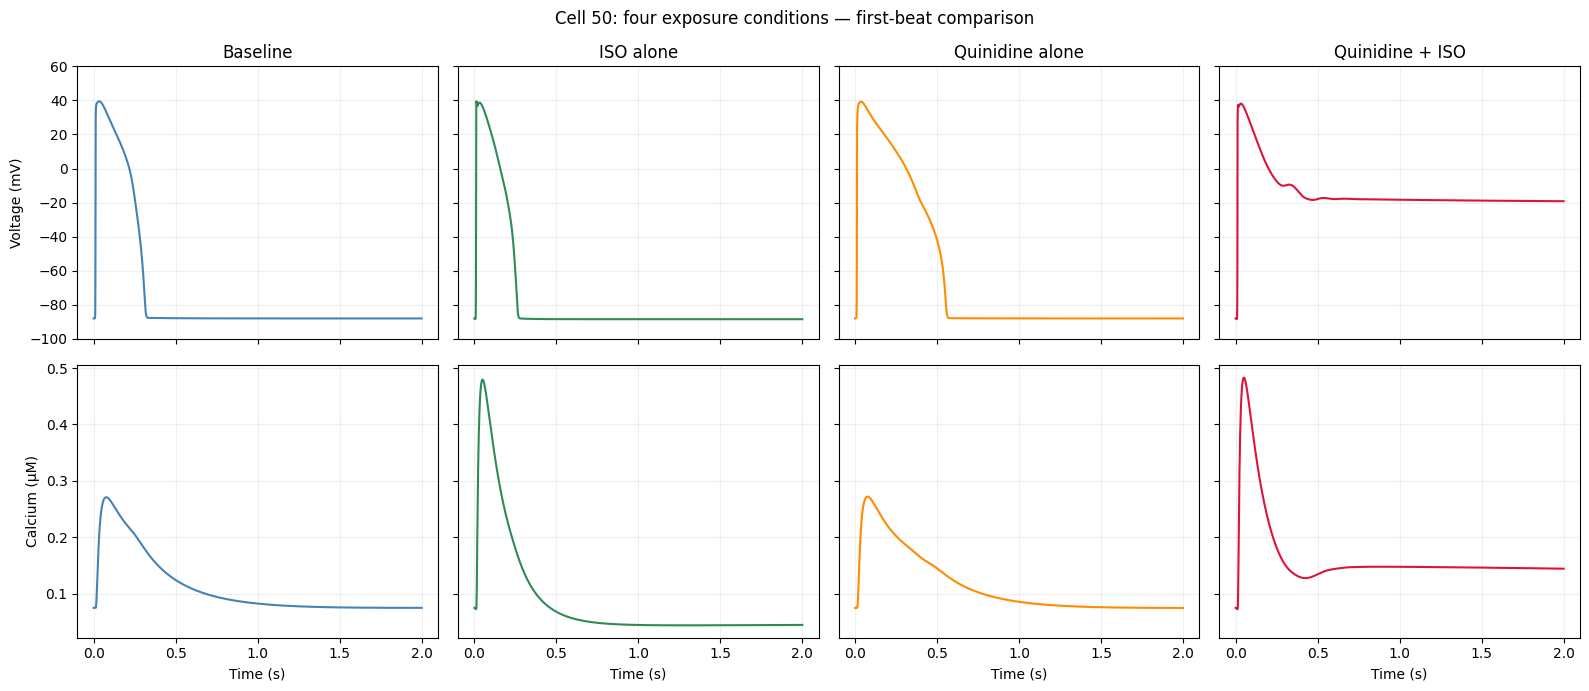

In [22]:
# compare voltage and calcium at cell 50 to see what reaches at the end of chain
condition_order = [
    "Baseline", "ISO alone",
    "Quinidine alone", "Quinidine + ISO"
]

colors = ["steelblue", "seagreen", "darkorange", "crimson"]

fig, axes = plt.subplots(
    2, 4, figsize=(16, 7),
    sharex=True, sharey="row"
)

for column, (label, color) in enumerate(
    zip(condition_order, colors)
):
    result = four_condition_results[label]
    time_s = result["time_ms"] / 1000

    axes[0, column].plot(
        time_s, result["voltage_mV"][:, -1],
        color=color
    )
    axes[1, column].plot(
        time_s, result["calcium_mM"][:, -1] * 1000,
        color=color
    )

    axes[0, column].set_title(label)
    axes[0, column].set_ylim(-100, 60)
    axes[1, column].set_xlabel("Time (s)")

    for row in range(2):
        axes[row, column].grid(alpha=0.2)

axes[0, 0].set_ylabel("Voltage (mV)")
axes[1, 0].set_ylabel("Calcium (µM)")

fig.suptitle(
    "Cell 50: four exposure conditions — first-beat comparison"
)
plt.tight_layout()
plt.show()

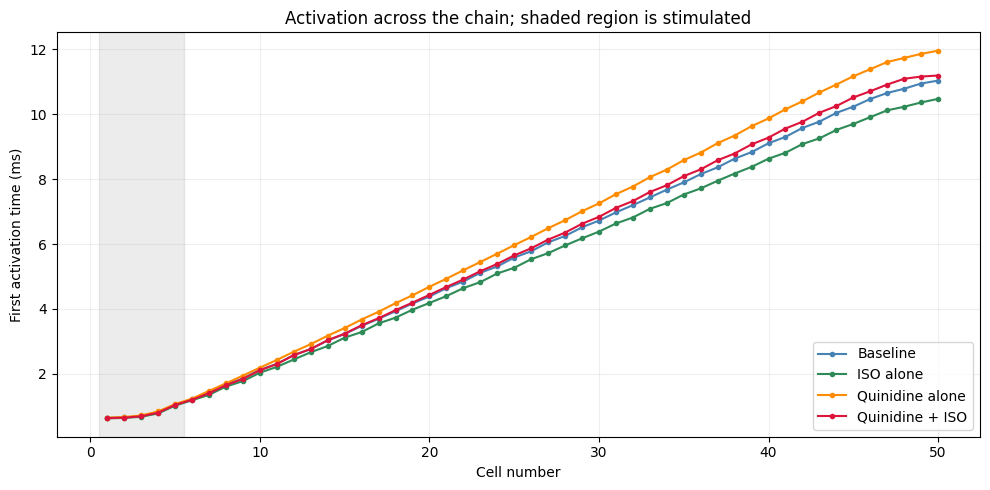

,Condition,Cells crossing -30 mV,Cell 50 activation (ms),Cell 50 peak (mV),Cell 50 final voltage (mV)
0,Baseline,50,11.039145,39.503140,-88.014138
1,ISO alone,50,10.475946,39.568724,-88.457401
2,Quinidine alone,50,11.961123,39.271269,-88.016731
3,Quinidine + ISO,50,11.196833,38.138156,-19.189554


In [23]:
# compare the activation sequence across conditions
fig, ax = plt.subplots(figsize=(10, 5))
rows = []

for label, color in zip(condition_order, colors):
    result = four_condition_results[label]
    activation = first_activation_times(result)
    cells = np.arange(1, len(activation) + 1)

    ax.plot(
        cells, activation, "o-",
        markersize=3, color=color, label=label
    )

    rows.append({
        "Condition": label,
        "Cells crossing -30 mV": int(
            np.isfinite(activation).sum()
        ),
        "Cell 50 activation (ms)": activation[-1],
        "Cell 50 peak (mV)": result["voltage_mV"][:, -1].max(),
        "Cell 50 final voltage (mV)": result["voltage_mV"][-1, -1],
    })

ax.axvspan(
    0.5, 5.5, color="gray", alpha=0.15
)
ax.set_xlabel("Cell number")
ax.set_ylabel("First activation time (ms)")
ax.set_title("Activation across the chain; shaded region is stimulated")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

comparison_summary = pd.DataFrame(rows)
display(comparison_summary)